In [3]:
import numpy as np
import wfdb
import os
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import class_weight
from tensorflow import keras
from tensorflow.keras import layers
import math

# Mamba block implementation (adapted for 1D ECG)
class MambaBlock(layers.Layer):
    def __init__(self, d_model, d_state=16, d_conv=4, expand=2, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model
        self.d_state = d_state
        self.d_conv = d_conv
        self.expand = expand
        self.norm = layers.LayerNormalization(epsilon=1e-6)
        self.conv1d = layers.Conv1D(filters=d_model, kernel_size=d_conv, padding="same", activation="relu")
        self.dense_expand = layers.Dense(d_model * expand, activation="gelu")
        self.dense_contract = layers.Dense(d_model)
        self.gate = layers.Dense(d_model * expand, activation="sigmoid")
        self.residual = layers.Add()

    def call(self, x):
        # x: (batch, seq_len, d_model)
        h = self.norm(x)
        h = self.conv1d(h)
        h_expand = self.dense_expand(h)
        h_gate = self.gate(h)
        h = h_expand * h_gate
        h = self.dense_contract(h)
        return self.residual([x, h])

# Load clean ECG data from the MIT-BIH Arrhythmia Database
def load_clean_ecg_data(data_path):
    records = [f.split('.')[0] for f in os.listdir(data_path) if f.endswith('.dat')]
    X, Y = [], []
    for record in records:
        signal, fields = wfdb.rdsamp(os.path.join(data_path, record))
        ann = wfdb.rdann(os.path.join(data_path, record), 'atr')
        for i in range(len(ann.sample)):
            if i == 0 or i == len(ann.sample) - 1:
                continue
            r_peak = ann.sample[i]
            start = r_peak - 100
            end = r_peak + 100
            if start < 0 or end > len(signal):
                continue
            heartbeat = signal[start:end, 0]
            X.append(heartbeat)
            Y.append(ann.symbol[i])
    return np.array(X), np.array(Y)

# Load noise data from the NSTDB
def load_noise_data(noise_path):
    noise_files = [f.split('.')[0] for f in os.listdir(noise_path) if f.endswith('.dat')]
    noise_signals = []
    for noise_file in noise_files:
        signal, fields = wfdb.rdsamp(os.path.join(noise_path, noise_file))
        noise_signals.append(signal[:, 0])
    return noise_signals

# Add noise to clean ECG signals with correct noise selection
def add_noise_to_ecg(ecg_signals, noise_signals, snr_db):
    noisy_ecg = []
    for ecg in ecg_signals:
        noise = noise_signals[np.random.randint(0, len(noise_signals))]
        if len(noise) > len(ecg):
            noise = noise[:len(ecg)]
        else:
            noise = np.pad(noise, (0, len(ecg) - len(noise)), 'wrap')
        rms_ecg = np.sqrt(np.mean(ecg**2))
        rms_noise = np.sqrt(np.mean(noise**2))
        desired_rms_noise = rms_ecg / (10**(snr_db / 20))
        noise = noise * (desired_rms_noise / rms_noise)
        noisy_ecg.append(ecg + noise)
    return np.array(noisy_ecg)

# Map labels to binary classes
def label_ecg(y):
    normal_classes = ['N', 'L', 'R']
    return 0 if y in normal_classes else 1

# Define Mamba-based model for ECG
def create_mamba_model(input_shape, d_model=64, num_blocks=2):
    inputs = keras.Input(shape=input_shape)
    x = layers.Conv1D(filters=d_model, kernel_size=3, padding="same", activation="relu")(inputs)
    x = layers.MaxPooling1D(pool_size=2)(x)
    for _ in range(num_blocks):
        x = MambaBlock(d_model)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Paths to the datasets
mitbih_path = "/kaggle/input/datasets/mahirazmainhaque/ecg-notebook-data/mit-bih-arrhythmia-database-1.0.0/mit-bih-arrhythmia-database-1.0.0"
nstdb_path = "/kaggle/input/datasets/mahirazmainhaque/ecg-notebook-data/mit-bih-noise-stress-test-database-1.0.0/mit-bih-noise-stress-test-database-1.0.0"

# Load and preprocess data
X_clean, Y_clean = load_clean_ecg_data(mitbih_path)
noise_signals = load_noise_data(nstdb_path)
X_noisy = add_noise_to_ecg(X_clean, noise_signals, snr_db=6)

# Normalize the data
scaler = StandardScaler()
X_noisy = np.array([scaler.fit_transform(x.reshape(-1, 1)).flatten() for x in X_noisy])

# Map labels
Y = np.array([label_ecg(y) for y in Y_clean])

# Train-test split
X_train, X_val, Y_train, Y_val = train_test_split(X_noisy, Y, test_size=0.2, random_state=42, stratify=Y)
X_val, X_test, Y_val, Y_test = train_test_split(X_val, Y_val, test_size=0.2, random_state=42, stratify=Y_val)
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]
X_val = X_val[..., np.newaxis]

# Create and train the Mamba model
model = create_mamba_model((X_train.shape[1], 1))

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(Y_train),
    y=Y_train
)
class_weight_dict = dict(enumerate(class_weights))

history = model.fit(X_train, Y_train, epochs=20, batch_size=32,
                    validation_data=(X_val, Y_val), class_weight=class_weight_dict)

# Evaluate the model
test_loss, test_acc = model.evaluate(X_test, Y_test)
print(f'Test Accuracy: {test_acc:.4f}')


2026-03-06 02:19:09.154309: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772763549.532418      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772763549.649299      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1772763550.510113      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772763550.510178      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772763550.510182      55 computation_placer.cc:177] computation placer alr

Epoch 1/20


I0000 00:00:1772763637.782963     129 service.cc:152] XLA service 0x798af8001dd0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1772763637.783000     129 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1772763637.783005     129 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1772763638.602802     129 cuda_dnn.cc:529] Loaded cuDNN version 91002


  33/2814 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.6341 - loss: 0.6347 

I0000 00:00:1772763643.274915     129 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2814/2814 ━━━━━━━━━━━━━━━━━━━━ 25s 6ms/step - accuracy: 0.8147 - loss: 0.4435 - val_accuracy: 0.9170 - val_loss: 0.2407
Epoch 2/20
2814/2814 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9074 - loss: 0.2838 - val_accuracy: 0.9251 - val_loss: 0.2317
Epoch 3/20
2814/2814 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9304 - loss: 0.2279 - val_accuracy: 0.9396 - val_loss: 0.1955
Epoch 4/20
2814/2814 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9385 - loss: 0.2047 - val_accuracy: 0.9381 - val_loss: 0.1904
Epoch 5/20
2814/2814 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9467 - loss: 0.1801 - val_accuracy: 0.9557 - val_loss: 0.1440
Epoch 6/20
2814/2814 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9514 - loss: 0.1675 - val_accuracy: 0.9554 - val_loss: 0.1349
Epoch 7/20
2814/2814 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9517 - loss: 0.1614 - val_accuracy: 0.9512 - val_loss: 0.1537
Epoch 8/20
2814/2814 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9528 - loss: 0.1519 - val

In [2]:
!pip install wfdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 3.9 MB/s eta 0:00:0000:01


Model saved to updated_ecg_transformer_model.keras


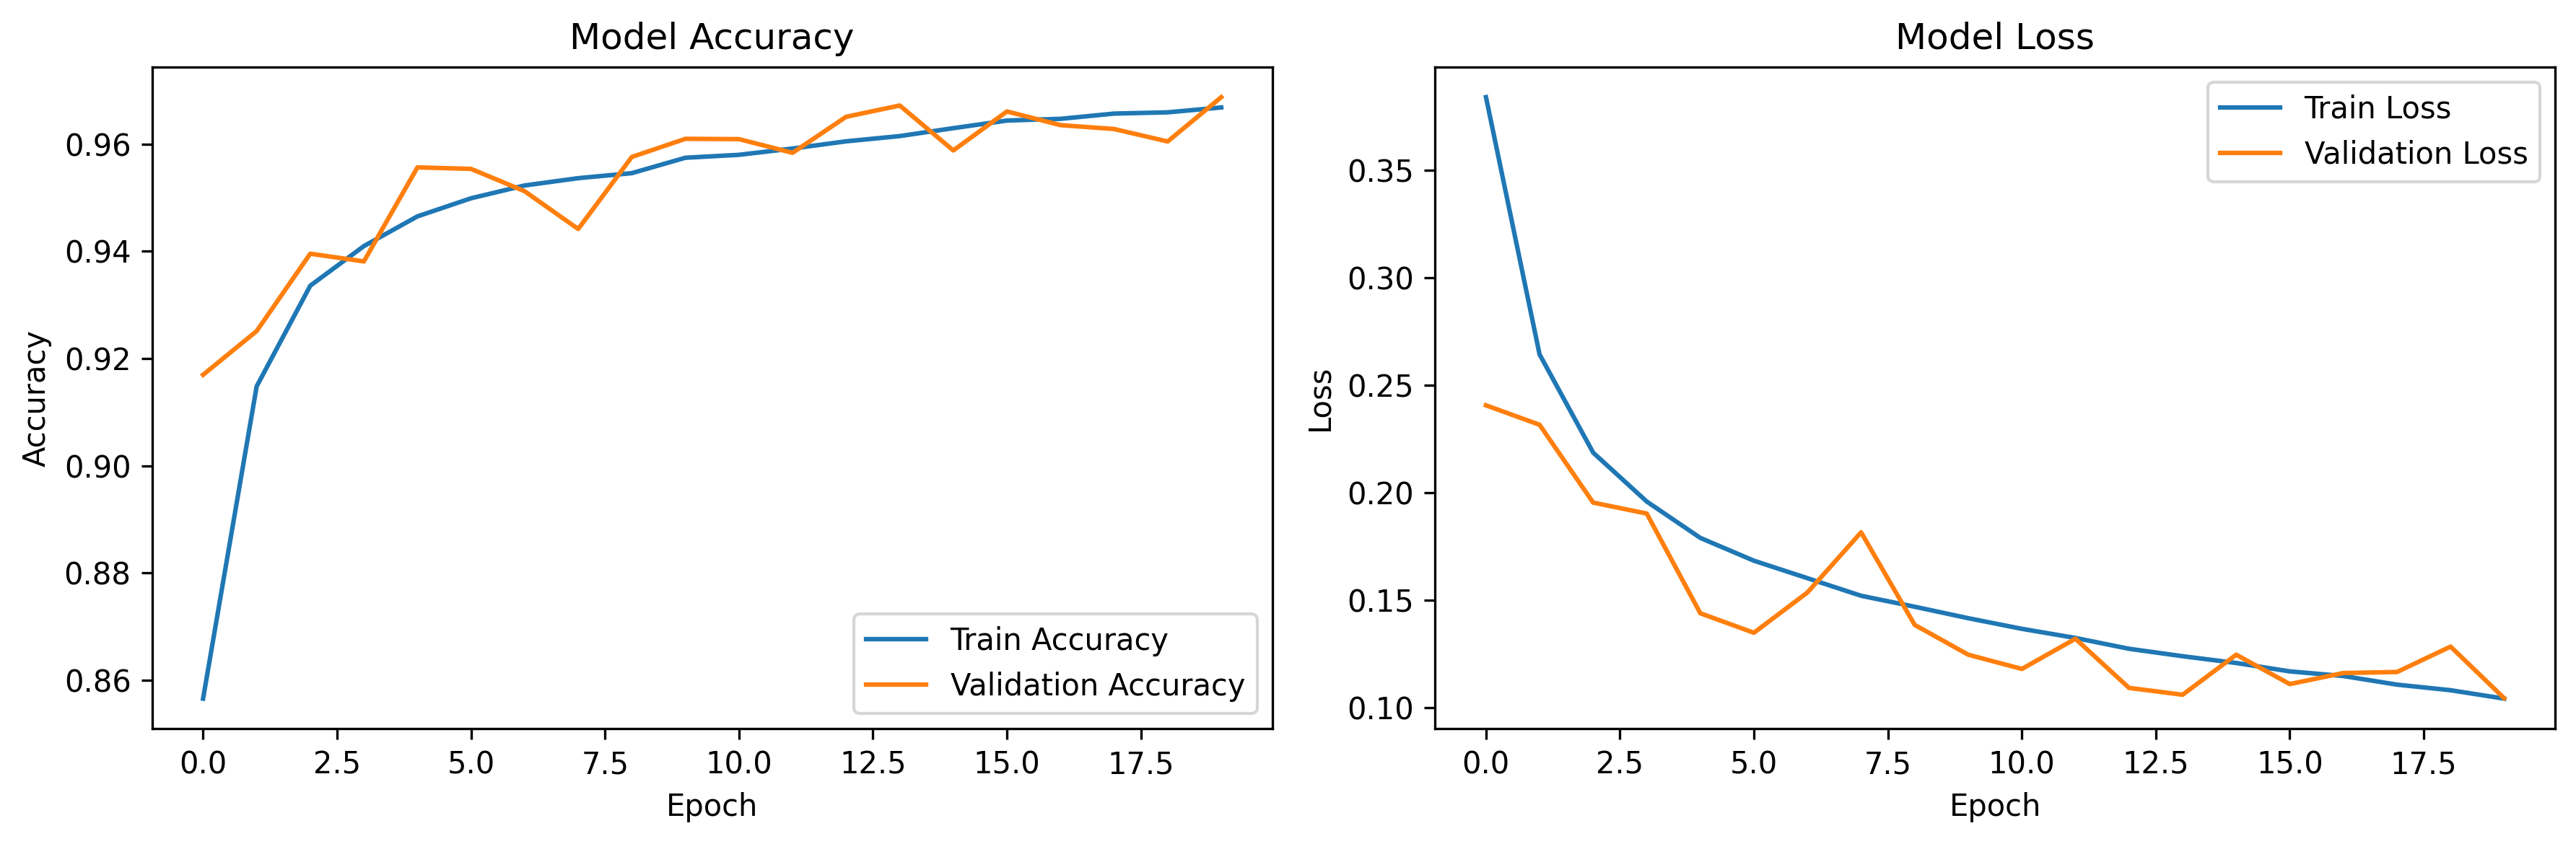

141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9662 - loss: 0.1009
Test Loss: 0.1004, Test Accuracy: 0.9682


In [4]:
import matplotlib.pyplot as plt

# Save the trained model
model_save_path = 'updated_ecg_transformer_model.keras'
model.save(model_save_path)
print(f"Model saved to {model_save_path}")

# Plot training history
def plot_training_history(history):
    # Plot Accuracy
    plt.figure(figsize=(12, 4),dpi=300)

    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss Plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    # Set DPI to 300
    plt.tight_layout()
    plt.savefig('ECG_model.png', dpi=300)
    plt.show()

# Call the function to plot the results
plot_training_history(history)

# Evaluate the model on the test set
test_loss, test_acc = model.evaluate(X_test, Y_test)
print(f'Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}')


In [5]:
from sklearn.metrics import classification_report, roc_curve, auc, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Predictions and metrics
y_pred_probs = model.predict(X_test)
y_pred = (y_pred_probs > 0.5).astype(int)

# Classification report
print("\nClassification Report:")
print(classification_report(Y_test, y_pred))




141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      3614
           1       0.92      0.92      0.92       888

    accuracy                           0.97      4502
   macro avg       0.95      0.95      0.95      4502
weighted avg       0.97      0.97      0.97      4502



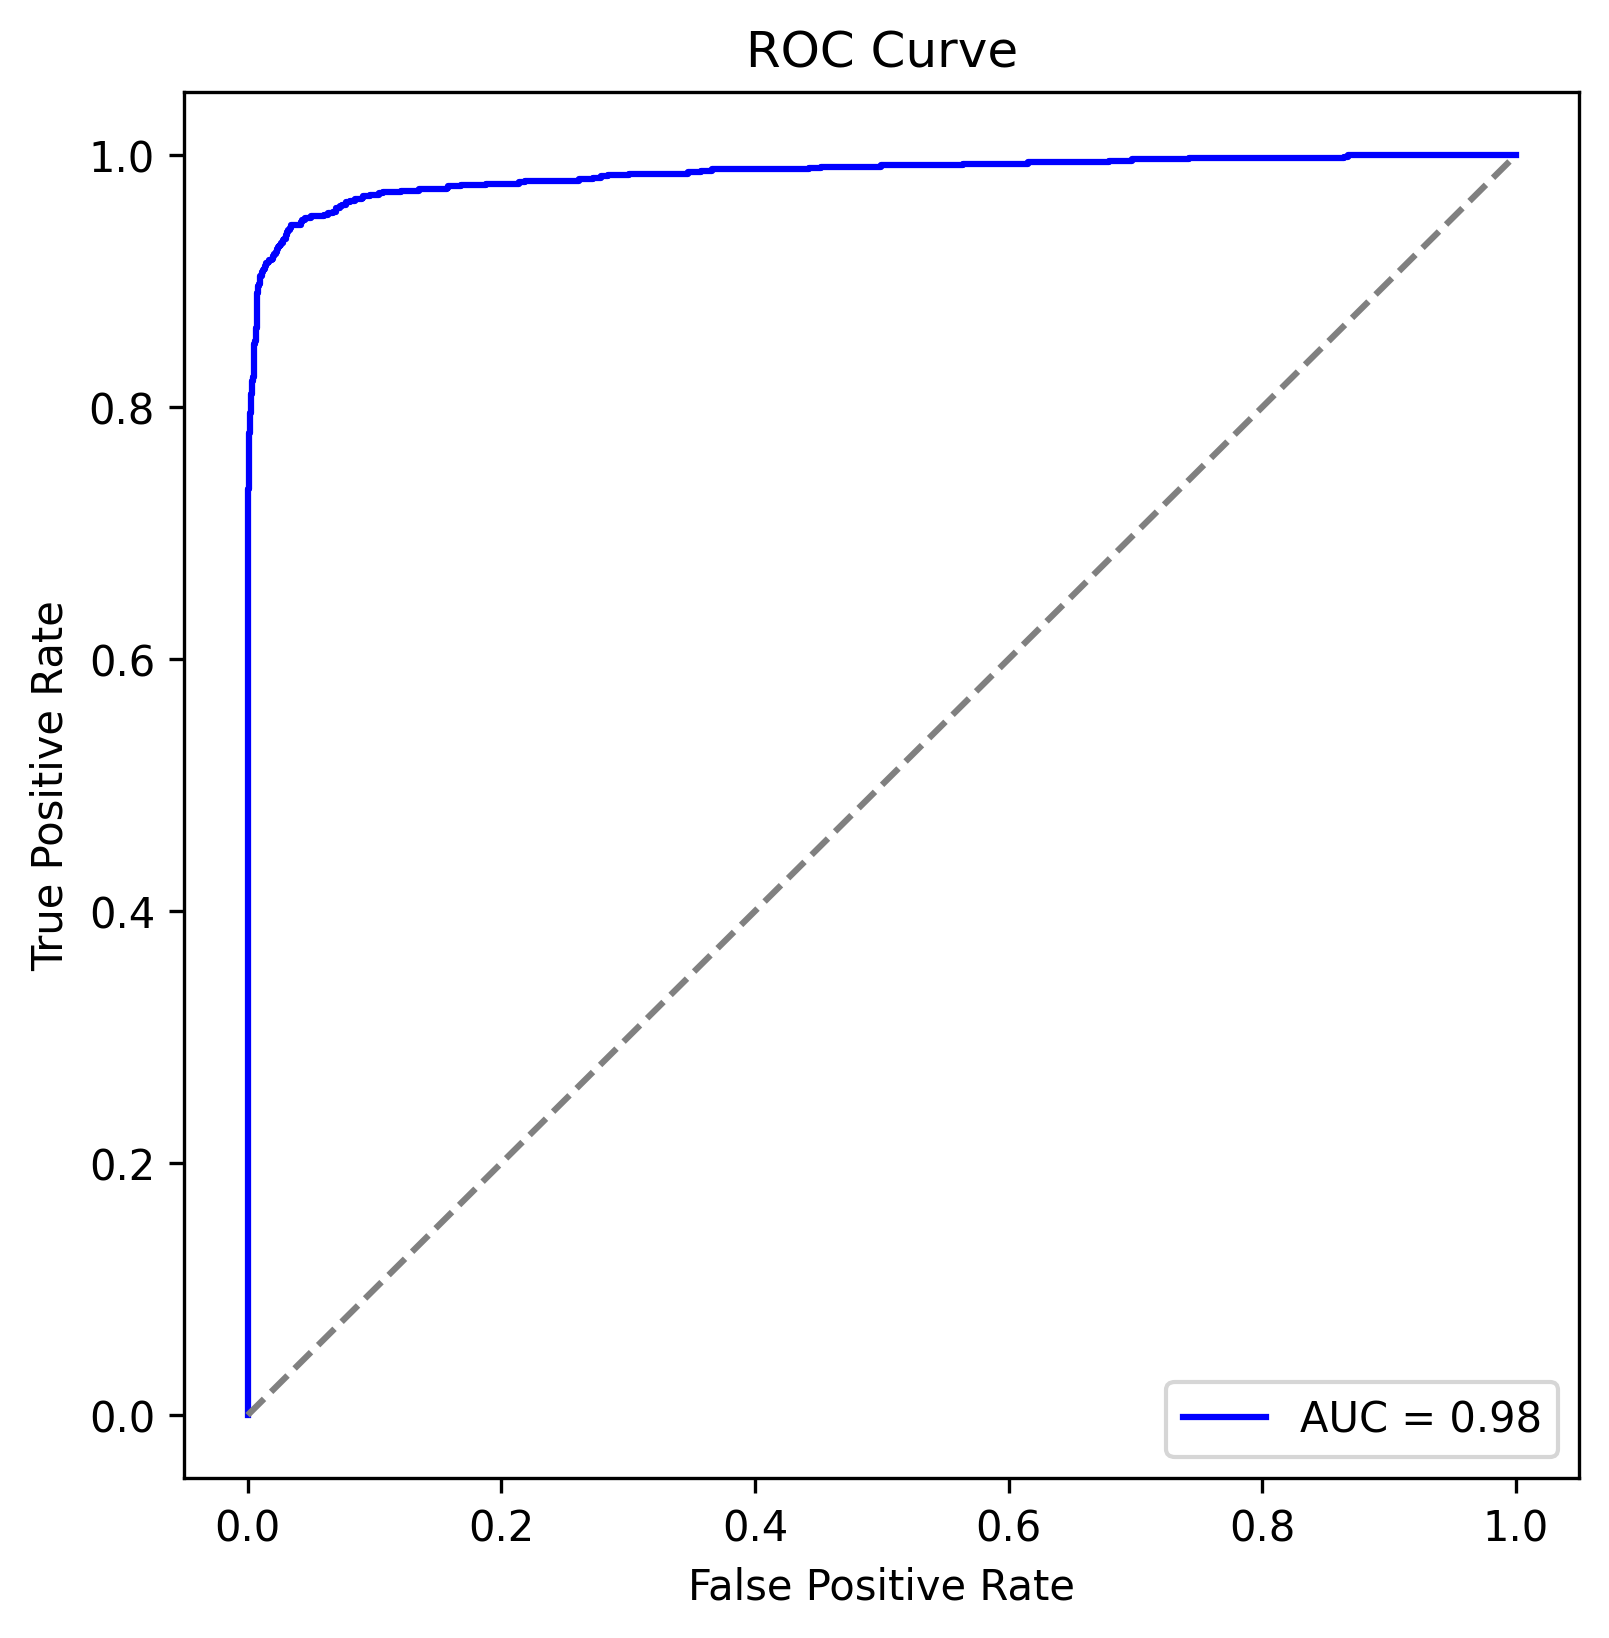

In [6]:

# ROC Curve
fpr, tpr, _ = roc_curve(Y_test, y_pred_probs)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6, 6), dpi=300)
plt.plot(fpr, tpr, color='blue', label=f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.savefig('roc_curve.png', dpi=300)
plt.show()


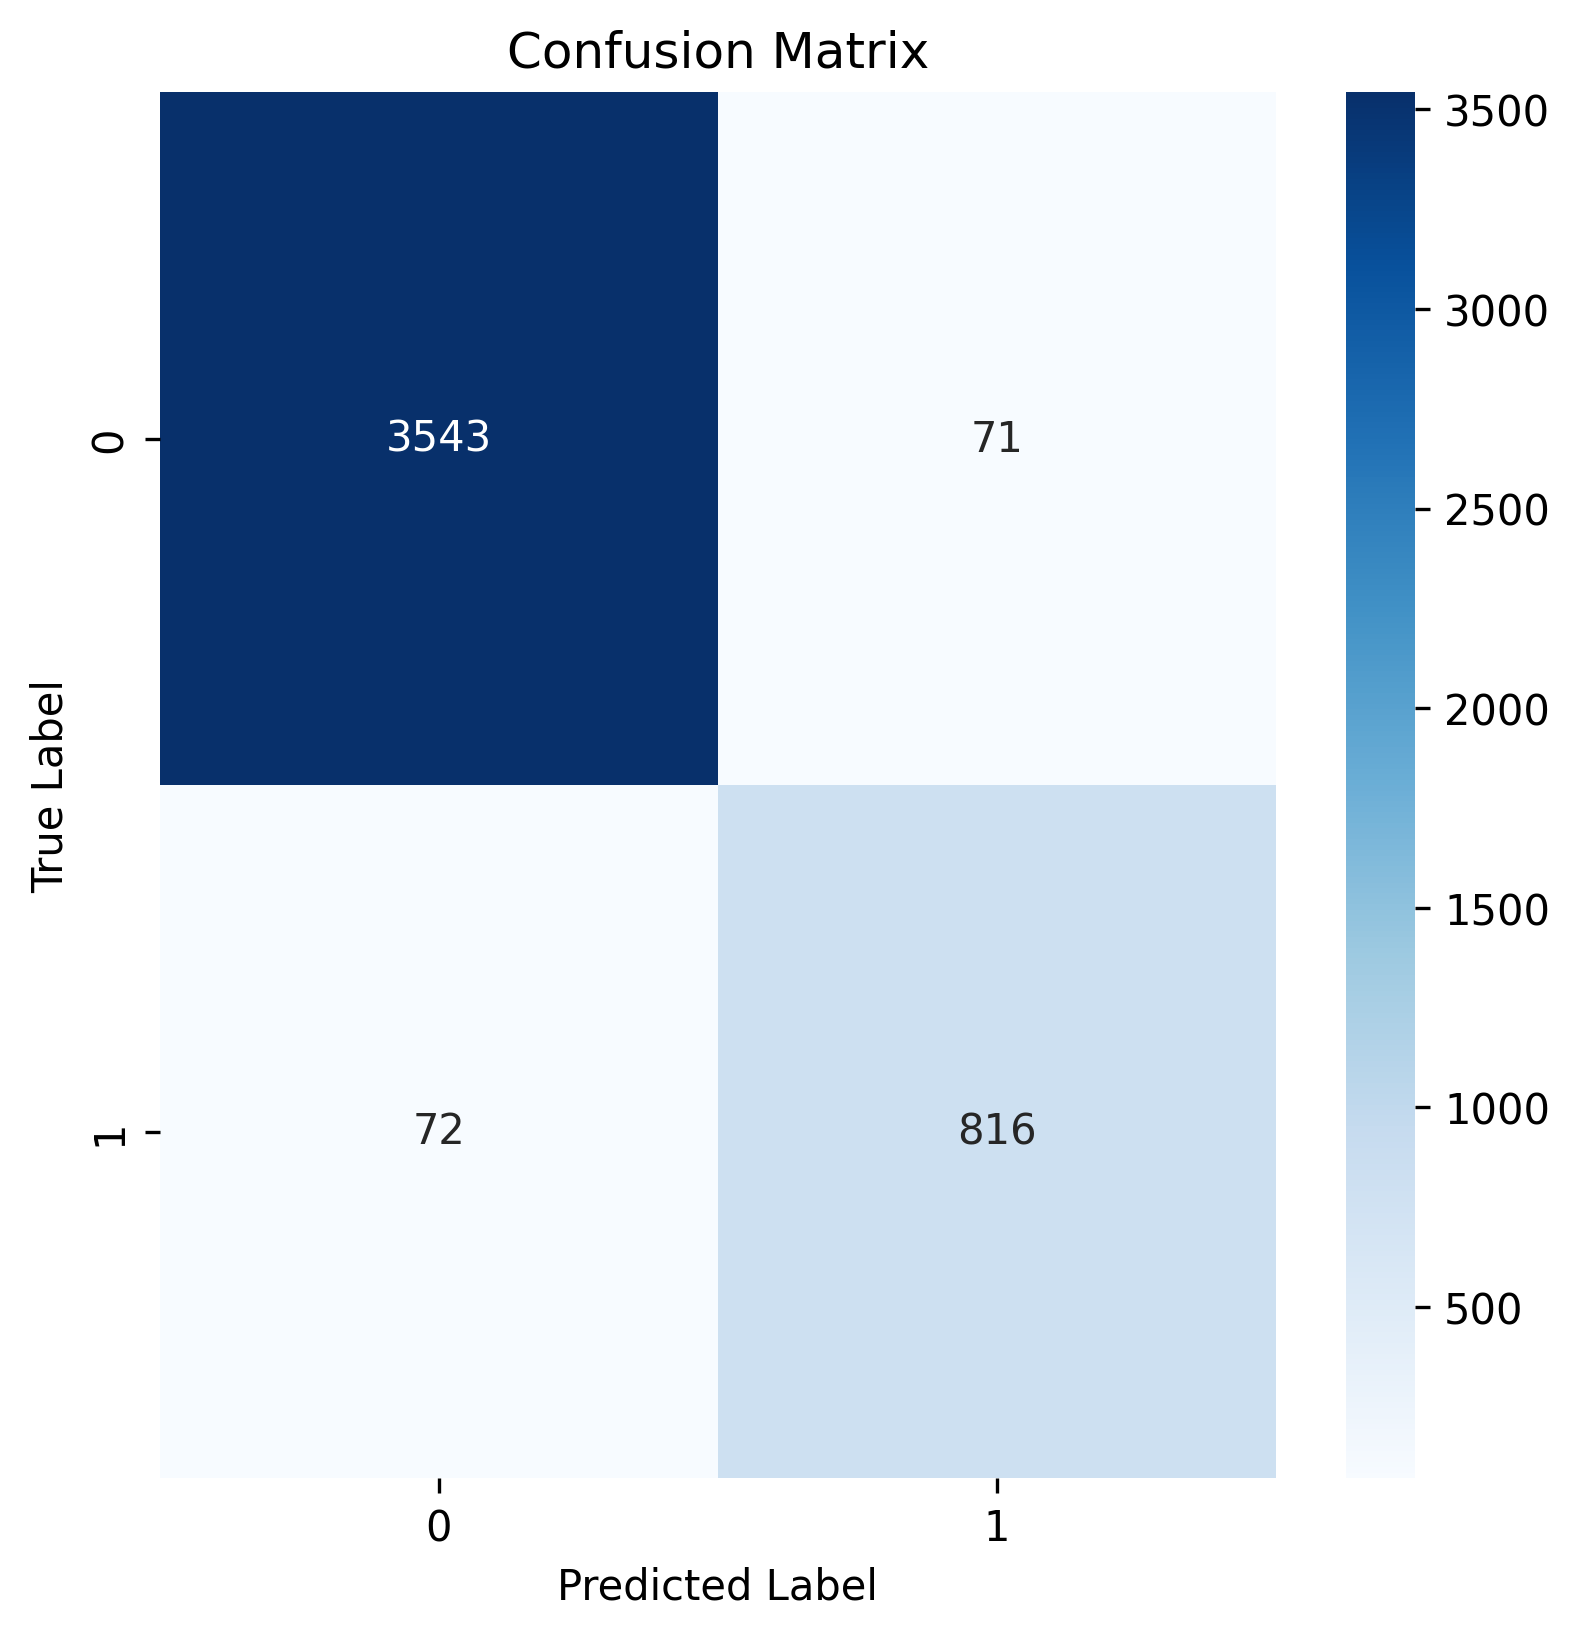

In [8]:
# Confusion Matrix
cm = confusion_matrix(Y_test, y_pred)
plt.figure(figsize=(6, 6), dpi=300)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()
